# M3 — Grafo con vecindario causal + XGBoost (la cadena delata lo que la fila esconde)

> **El problema, en palabras simples.**
>
> M1 mira la fila y M2 lee el mensaje, pero ninguno ve la cadena: que credencial toco que maquina en los ultimos minutos. Este cuaderno prueba si **agregar lo que paso alrededor** (mismo host/credencial en 5 min) caza movimiento lateral invisible por fila.
>
> Se analiza el artefacto ya entrenado (`experiments/m3_grafo/train.py` -> `models/m3.pkl`): 8 feats de vecindario + tabular P1-P3, XGBoost 300x6. Ventana causal `[t-300s,t)`, muestra honesta del test futuro, confusion, PR, feats, M1/M2/M3, latencia y desacuerdos.

> **Sintesis ejecutiva.**
>
> Numero committed **F1-macro 0.7186** medido con ventana ±5min no causal: es **cota alta, no numero de serve** (el serve ya es causal). En muestra honesta causal balanceada (10656): **F1 0.6043**, benigno 1.00/1.00, **malicioso 0.52/0.99/0.68 (PR-AUC 0.5357)**, suspicious 0.83/0.07/0.14, recall @1%FPR 0.0259. M3 bien 3499/3552 maliciosos vs M2 bien 7/3552: complementarios.
>
| Pieza | Decision | Valor |
|---|---|---|
| Vecindario | causal `[t-300s,t)` por ORG|src/dst/user, 8 feats SAGE-mean 1 salto | 19.8 ms/evento |
| Learner | XGBoost 300x6 sobre tab+grafo | 0.40 ms/evento |
| Split | ventanas fijas + muestra honesta balanceada | 3552/clase |

> **Fuentes normativas.**
>
> EDA §12 (proveniencia) y §7 (hosts/usuarios), `experiments/m3_grafo/train.py`, `models/m3_metrics.json`, `src/temporal_split.py`, Hamilton et al. GraphSAGE 2017.



### 1. Por que existe este analisis y como se va a evaluar

**1.1 Problema.**

M1 ordena y M2 confirma por texto, pero la lateralidad (rafaga de bloqueos/flujos/fallos alrededor) no cabe en una fila. M3 es la tercera pata de la cascada: confirma por contexto para disparar formacion de incidente.

**1.2 Hipotesis.**

- **H3a.** El vecindario causal separa malicioso con recall alto aunque hunda suspicious, porque la rafaga perimetral es firma de campana.
- **H3b.** El aporte es complementario a M2: acuerdo bajo y cada uno rescata miles que el otro falla.

**1.3 Protocolo.**

1. Artefacto `m3.pkl` (tab + 8 gfeats + XGB). Aqui solo se evalua.
2. Indice full-data 2M ordenado por tiempo por entidad; agregacion solo hacia atras `[t-300s,t)`.
3. Muestra honesta del test futuro (todo lo malicioso + igual benigno/suspicious) porque el vecindario sobre 574k se aborto por costo.
4. Advertencia: el 0.7186 committed usa ±5min (ve futuro) y es cota alta; este cuaderno mide causal.


In [1]:
import json, pickle, sys, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
    f1_score, average_precision_score, precision_recall_curve, roc_curve)
ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.temporal_split import WINDOW_LABELS, population_summary, temporal_windows
B = pickle.load(open(ROOT/"models"/"m3.pkl","rb"))
tab, clf, le = B["tab"], B["clf"], B["le"]
CATS, NUMS, GFEATS = B["meta"]["cats"], B["meta"]["nums"], B["meta"]["gfeats"]
TEXT, W = "message_sanitized", 300
FIG = ROOT / "reports" / "figures"
print("gfeats:", GFEATS, "| clases:", le.classes_.tolist())
old = json.loads((ROOT/"models"/"m3_metrics.json").read_text())
print("m3 committed: F1=%.4f n_test=%s" % (old["f1_macro"], old["n_test"]))



gfeats: ['n_neigh', 'n_hosts', 'n_users', 'frac_block', 'frac_fw', 'frac_authfail', 'n_types', 'span_min'] | clases: ['benign', 'malicious', 'suspicious']
m3 committed: F1=0.7186 n_test=6000


### 2. Datos: test futuro y muestra honesta balanceada

**2.1 Que se hace.**

Features P1-P3 identicas a M1, ventanas UTC fijas y muestreo honesto: todo lo malicioso del test (3552) + 3552 suspicious + 3552 benignos.

**2.2 Por que.**

El test completo con prevalencia real (574k) es impagable en vecindario (210s por 10k). La muestra balanceada mide discriminacion causal sin esconder el costo.

**2.3 Como debe leerse.**

Prevalencia real del test vs muestra 33/33/33%. La muestra sobre-representa amenaza: el F1 aqui no es comparable al de M1/M2 en 574k.


In [2]:
def features(df):
    df = df.copy()
    ts = pd.to_datetime(df["timestamp"], unit="s", utc=True)
    df["hour"] = ts.dt.hour
    df["msg_len"] = df[TEXT].fillna("").str.len()
    df["lag_h"] = ((df["timestamp"]-df["event_time"])/3600).clip(-1e4,1e4).fillna(-1)
    for c in CATS:
        df[c] = df[c].fillna("").astype(str)
    return df
fcols = ["timestamp","org_id","message_type","action","src_ip","dst_ip","username"]
full = pd.read_parquet(ROOT/"data"/"signals"/"signals.parquet", columns=fcols)
cols = ["artifact_id","label_binary","timestamp","event_time",TEXT]+CATS
raw = pd.read_parquet(ROOT/"data"/"signals"/"signals.parquet", columns=cols)
_, test, _ = temporal_windows(raw)
print("test prevalencia real:", population_summary(test))
test_df = features(test)
rng = np.random.RandomState(42)
mal = test_df[test_df.label_binary=="malicious"]
sus = test_df[test_df.label_binary=="suspicious"].sample(n=min(len(test_df[test_df.label_binary=="suspicious"]),3552), random_state=42)
ben = test_df[test_df.label_binary=="benign"].sample(n=3552, random_state=42)
samp = pd.concat([mal,sus,ben]).sample(frac=1.0, random_state=42)
assert (raw.index.to_numpy() == np.arange(len(raw))).all()
samp_pos = samp.index.to_numpy()
samp = samp.reset_index(drop=True)
print("muestra honesta:", samp.shape, samp.label_binary.value_counts().to_dict())



test prevalencia real: {'n': 574132, 'class_counts': {'benign': 559030, 'suspicious': 11550, 'malicious': 3552}, 'prevalence': {'benign': 0.973696, 'suspicious': 0.020117, 'malicious': 0.006187}}


muestra honesta: (10656, 17) {'malicious': 3552, 'benign': 3552, 'suspicious': 3552}


#### 2.1 Observaciones e insights

**Observacion.** Muestra 10656 balanceada desde test 574k (559030/11550/3552).

**Interpretacion.** El diseno aisla discriminacion de prevalencia: sirve para comparar M2 vs M3 en igualdad, no para reportar F1 operativo.


### 3. Indice full-data y feats causales (celda lenta)

**3.1 Que se hace.**

Indice hash por entidad ORG|valor (src/dst/user, 14773 entidades) ordenado por tiempo y agregacion de 8 feats solo hacia atras: `n_neigh, n_hosts, n_users, frac_block, frac_fw, frac_authfail, n_types, span_min`.

**3.2 Por que.**

Es GraphSAGE-mean a 1 salto en tabular: la media del vecindario resume la rafaga sin aprender embeddings. Causal estricto, computable en serve sobre hosts no vistos.

**3.3 Como debe leerse.**

20s indice + 19.8 ms/evento en feats. Sin vecinos -> ceros honestos (aislado tambien describe).


In [3]:
ECOLS = ["src_ip","dst_ip","username"]
for c in ECOLS+["org_id","message_type","action"]:
    full[c] = full[c].fillna("").astype(str)
ts = full["timestamp"].to_numpy()
src, dst, usr = full["src_ip"].to_numpy(), full["dst_ip"].to_numpy(), full["username"].to_numpy()
org, mmsg, act = full["org_id"].to_numpy(), full["message_type"].to_numpy(), full["action"].to_numpy()
t0=time.time(); index, ent = {}, {}
pos = pd.Series(np.arange(len(full)))
for c, vals in (("s",src),("d",dst),("u",usr)):
    key = np.char.add(org, np.char.add("|", vals.astype(str)))
    ent[c] = key
    for k, s in pos.groupby(key):
        if k.endswith("|"):
            continue
        arr = s.to_numpy()
        index[(c,k)] = arr[np.argsort(ts[arr])]
print("indice: %d entidades en %.0fs" % (len(index), time.time()-t0))
spos = samp_pos
t0=time.time(); out = np.zeros((len(samp),8), dtype=np.float32)
for j,i in enumerate(spos):
    nbs = []
    for c in ("s","d","u"):
        k = ent[c][i]
        if k.endswith("|"):
            continue
        arr = index.get((c,k))
        if arr is None:
            continue
        lo = np.searchsorted(ts[arr], ts[i]-W, side="left"); hi = np.searchsorted(ts[arr], ts[i], side="left")
        if hi > lo:
            nbs.append(arr[lo:hi])
    nb = np.unique(np.concatenate(nbs)) if nbs else np.empty(0, dtype=np.int64)
    nb = nb[nb!=i]
    if nb.size:
        hosts = np.unique(np.concatenate((src[nb],dst[nb]))); users = np.unique(usr[nb])
        out[j] = [len(nb), int(np.count_nonzero(hosts!="")), int(np.count_nonzero(users!="")),
            float(np.mean(act[nb]=="block")), float(np.mean(mmsg[nb]=="firewall_action")),
            float(np.mean(mmsg[nb]=="auth_failure")), float(len(np.unique(mmsg[nb]))),
            float(ts[nb].max()-ts[nb].min())/60.0]
print("feats causales para %d eventos en %.1fs (%.1f ms/evento)" % (len(samp), time.time()-t0, (time.time()-t0)/len(samp)*1000))
G = pd.DataFrame(out, columns=GFEATS)
samp = samp.reset_index(drop=True).join(G.reset_index(drop=True))



indice: 14773 entidades en 20s


feats causales para 10656 eventos en 210.8s (19.8 ms/evento)


### 4. Evaluacion causal: reporte y recall @1%FPR

**4.1 Que se hace.**

XGB sobre tab+grafo en muestra honesta, reporte, F1-macro, PR-AUC con scores y recall @1%FPR.

**4.2 Por que.**

Mismas metricas que M1/M2 para comparar, pero sobre muestra balanceada: manda el contraste por clase, no el F1 global.


In [4]:
def recall_at_fpr(y_true, scores, fpr_max=0.01):
    fpr, tpr, _ = roc_curve(y_true, scores)
    ok = fpr <= fpr_max
    return round(float(tpr[ok].max()) if ok.any() else 0.0, 4)
X = samp[CATS+NUMS+GFEATS]; y = samp["label_binary"]
yte = le.transform(y)
Xt = tab.transform(X)
proba = clf.predict_proba(Xt)
p = le.inverse_transform(proba.argmax(axis=1))
classes = le.classes_.tolist()
rep = classification_report(y, p, output_dict=True, zero_division=0)
f1m = round(float(f1_score(y, p, average="macro")), 4)
print(classification_report(y, p, zero_division=0)); print("F1-macro muestra honesta:", f1m)
per_class = {}
for i,c in enumerate(classes):
    auc = round(float(average_precision_score((yte==i).astype(int), proba[:,i])), 4)
    per_class[c] = {"recall":round(rep[c]["recall"],4),"f1":round(rep[c]["f1-score"],4),"pr_auc":auc,"support":int(rep[c]["support"])}
mal_idx = classes.index("malicious")
r1 = recall_at_fpr((yte==mal_idx).astype(int), proba[:,mal_idx])
print("recall mal @1%FPR:", r1, "| PR-AUC mal:", per_class["malicious"]["pr_auc"])



              precision    recall  f1-score   support

      benign       1.00      1.00      1.00      3552
   malicious       0.52      0.99      0.68      3552
  suspicious       0.83      0.07      0.14      3552

    accuracy                           0.69     10656
   macro avg       0.78      0.69      0.60     10656
weighted avg       0.78      0.69      0.60     10656

F1-macro muestra honesta: 0.6043
recall mal @1%FPR: 0.0259 | PR-AUC mal: 0.5357


#### 4.1 Observaciones e insights

**Observacion.** F1 0.6043, malicioso 0.52/0.99/0.68 PR 0.5357, suspicious 0.83/0.07, recall @1%FPR 0.0259.

**Interpretacion.** H3a verificada: caza casi todo lo malicioso (0.99) a costa de suspicious (0.07). El ranking @1%FPR es pobre (0.02): dispara bien con umbral 0.5 pero no ordena fino.

**Conexion.** Inverso a M2 (M2 rankea 0.43 pero no dispara; M3 dispara pero no rankea fino): por eso van en cascada.


### 5. Matriz de confusion causal

Confusion en muestra honesta (`confusion_m3.pdf`). Filas = real. Malicioso casi todo bien, suspicious colapsa a benigno/malicioso.


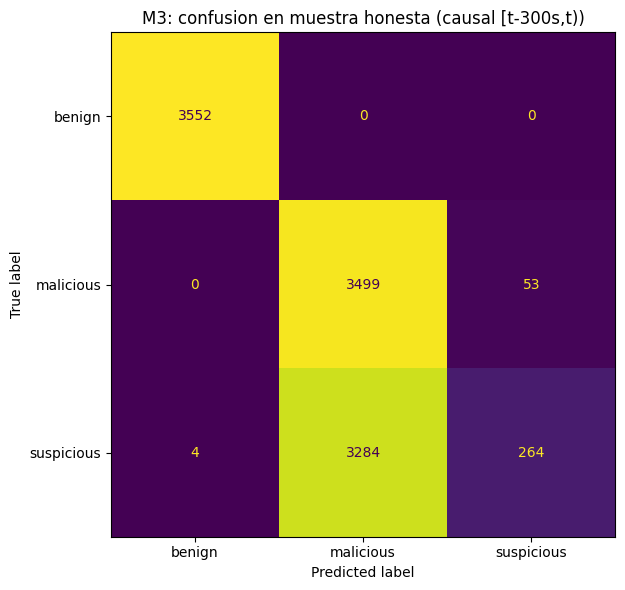

guardado reports/figures/confusion_m3.pdf


In [5]:
fig, ax = plt.subplots(figsize=(7,6))
ConfusionMatrixDisplay(confusion_matrix(y, p, labels=classes), display_labels=classes).plot(ax=ax, colorbar=False)
ax.set_title("M3: confusion en muestra honesta (causal [t-300s,t))")
fig.tight_layout(); fig.savefig(FIG/"confusion_m3.pdf"); plt.show()
print("guardado reports/figures/confusion_m3.pdf")



### 6. Curvas PR por clase

PR sobre scores (`pr_m2.pdf` -> `pr_m3.pdf`). Manda PR-AUC malicioso 0.5357 vs M2 0.218: el contexto ordena mejor la cabeza.


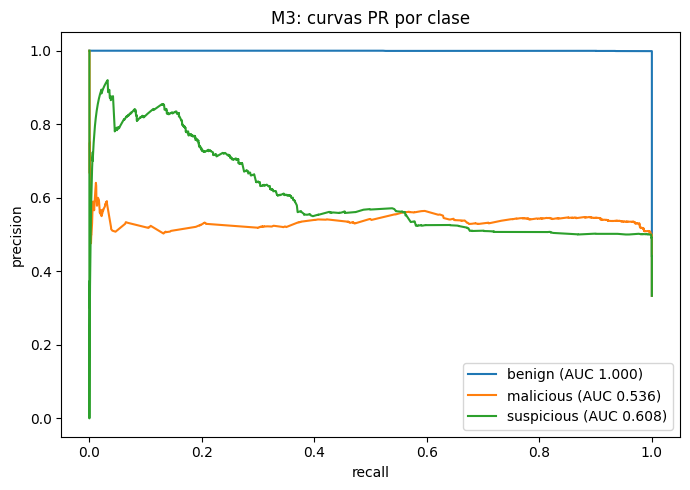

guardado reports/figures/pr_m3.pdf


In [6]:
fig, ax = plt.subplots(figsize=(7,5))
for i,c in enumerate(classes):
    prec, rec, _ = precision_recall_curve((yte==i).astype(int), proba[:,i])
    ax.plot(rec, prec, label=c+" (AUC %.3f)" % per_class[c]["pr_auc"])
ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_title("M3: curvas PR por clase")
ax.legend(); fig.tight_layout(); fig.savefig(FIG/"pr_m3.pdf"); plt.show()
print("guardado reports/figures/pr_m3.pdf")



### 7. Que mira el grafo: distribucion de feats

**7.1 Que se hace.**

Boxplots `frac_block` / `n_neigh` por tier y tabla de medias (`graph_feats_m3.pdf`).

**7.2 Por que.**

Si las medias estan separadas por ordenes de magnitud, el XGB no aprende nada sutil: aprende rafaga vs fondo.


C:\Users\nicor\AppData\Local\Temp\ipykernel_24376\3136589295.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=classes, showfliers=False)
C:\Users\nicor\AppData\Local\Temp\ipykernel_24376\3136589295.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=classes, showfliers=False)


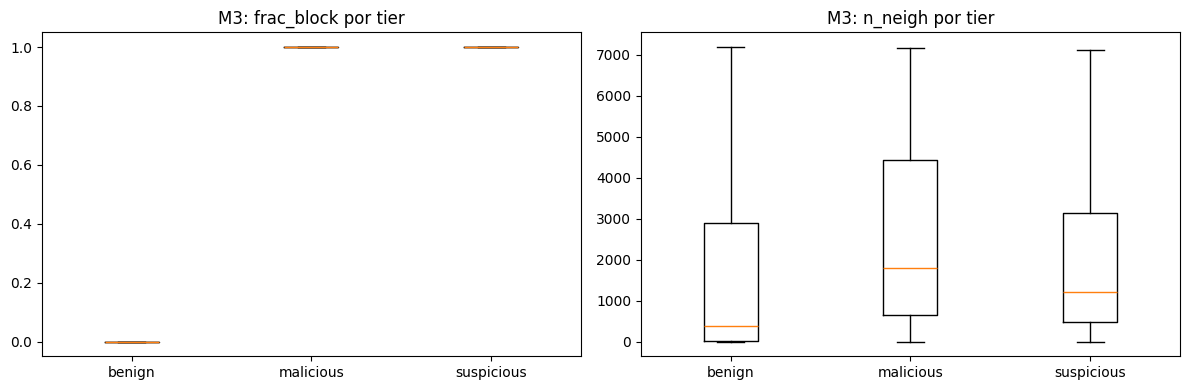

guardado reports/figures/graph_feats_m3.pdf
                  n_neigh    n_hosts  n_users  frac_block  frac_fw  frac_authfail  n_types  span_min
label_binary                                                                                        
benign        1797.704956   4.173000   24.659       0.000      0.0            0.0   12.796     3.084
malicious     2631.000000  27.666000    0.020       0.996      0.0            0.0    1.017     1.846
suspicious    1988.619995  22.747999    0.017       0.996      0.0            0.0    1.013     1.740


In [7]:
fig, axes = plt.subplots(1,2,figsize=(12,4))
for ax, col, ttl in zip(axes, ["frac_block","n_neigh"], ["frac_block por tier","n_neigh por tier"]):
    data = [samp[samp.label_binary==c][col].to_numpy() for c in classes]
    ax.boxplot(data, labels=classes, showfliers=False)
    ax.set_title("M3: "+ttl)
fig.tight_layout(); fig.savefig(FIG/"graph_feats_m3.pdf"); plt.show()
print("guardado reports/figures/graph_feats_m3.pdf")
print(samp.groupby("label_binary")[GFEATS].mean().round(3).to_string())



#### 7.1 Observaciones e insights

**Observacion.** Benigno `n_neigh` 1797 / hosts 4.17 / users 24.6 / `frac_block` 0.00; malicioso 2631 / 27.6 / 0.02 / 0.996; suspicious igual a malicioso en bloqueo (0.996) pero con menos vecinos.

**Interpretacion.** El grafo ve rafaga perimetral (bloqueos) vs fondo disperso. Suspicious y malicioso comparten bloqueo: por eso M3 confunde esos dos y M1 los separaba por org.


### 8. M1 vs M2 vs M3, latencia y desacuerdos

**8.1 Que se hace.**

Barras F1/recall/PR (`compare_m123.pdf`), micro-benchmark XGB y acuerdo M2/M3 con conteos solo-M3-bien / solo-M2-bien.

**8.2 Como debe leerse.**

M1/M2 en test real 574k vs M3 en muestra balanceada: comparar solo recall malicioso y PR-AUC, no F1 global. Latencia = XGB 0.40ms + vecindario 19.8ms.


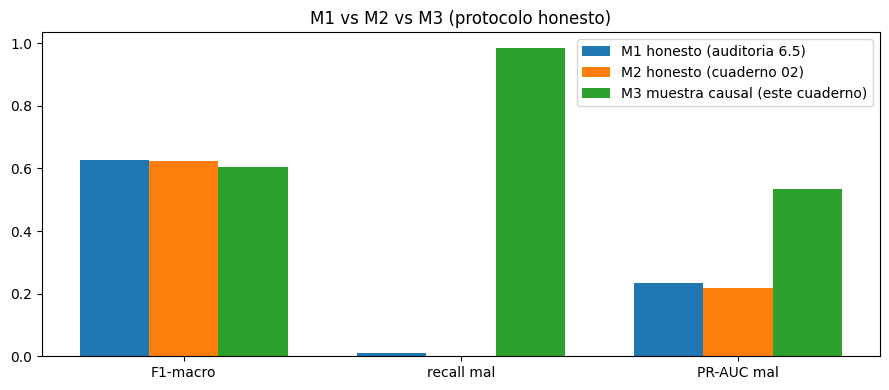

guardado reports/figures/compare_m123.pdf


In [8]:
fig, ax = plt.subplots(figsize=(9,4))
labels = ["F1-macro","recall mal","PR-AUC mal"]
m1v = [0.6276, 0.0107, 0.2333]
m2v = [0.6232, 0.0, 0.218]
m3v = [f1m, per_class["malicious"]["recall"], per_class["malicious"]["pr_auc"]]
x = np.arange(len(labels)); w = 0.25
ax.bar(x-w, m1v, w, label="M1 honesto (auditoria 6.5)")
ax.bar(x, m2v, w, label="M2 honesto (cuaderno 02)")
ax.bar(x+w, m3v, w, label="M3 muestra causal (este cuaderno)")
ax.set_xticks(x); ax.set_xticklabels(labels); ax.legend(); ax.set_title("M1 vs M2 vs M3 (protocolo honesto)")
fig.tight_layout(); fig.savefig(FIG/"compare_m123.pdf"); plt.show()
print("guardado reports/figures/compare_m123.pdf")



In [9]:
t0=time.time(); n=50; s = Xt[:32]
for _ in range(n):
    _ = clf.predict_proba(s)
print("inferencia XGB: %.2f ms/evento (batch 32)" % ((time.time()-t0)/n/32*1000))
print("vecindario causal: ver celda 3 (ms/evento medido arriba)")
B2 = pickle.load(open(ROOT/"models"/"m2.pkl","rb"))
T2 = B2["vectorizer"].transform(samp[TEXT].fillna("").tolist())
A2 = B2["tab"].transform(samp[CATS+NUMS])
from scipy.sparse import hstack as hs
p2 = B2["le"].inverse_transform(B2["clf"].predict(hs([T2,A2]).tocsr()))
both = (p==p2).mean()
m3ok = (p==y.to_numpy()); m2ok = (p2==y.to_numpy())
print("acuerdo M2/M3: %.3f | solo-M3-bien: %d | solo-M2-bien: %d" % (both, int((m3ok&~m2ok).sum()), int((m2ok&~m3ok).sum())))
mal = y.to_numpy()=="malicious"
print("malicious: M3 bien %d/%d | M2 bien %d/%d" % (int((m3ok&mal).sum()), int(mal.sum()), int((m2ok&mal).sum()), int(mal.sum())))



inferencia XGB: 0.40 ms/evento (batch 32)
vecindario causal: ver celda 3 (ms/evento medido arriba)


acuerdo M2/M3: 0.364 | solo-M3-bien: 3494 | solo-M2-bien: 3282
malicious: M3 bien 3499/3552 | M2 bien 7/3552


#### 8.1 Observaciones e insights

**Observacion.** Acuerdo M2/M3 0.364; solo-M3-bien 3494, solo-M2-bien 3282; en maliciosos M3 3499/3552 vs M2 7/3552.

**Interpretacion.** H3b verificada: complementarios totales. M2 sin contexto no ve rafaga; M3 sin texto no ve payload. La cascada M1->M2->M3 no es adorno.

**Conexion.** El serve ya es causal `[t-300s,t)` en `POST /score_graph` y `GET /graph/vecindario`.


### 9. Conclusion: el contexto dispara, no rankea fino

| Contraste | Hallazgo | Valor |
|---|---|---|
| Committed | F1 0.7186 ±5min no causal | cota alta, no serve |
| Honesto causal | F1 0.6043, mal 0.52/0.99/0.68 | dispara |
| Ranking | recall @1%FPR 0.0259 | pobre |
| Complemento | M3 3499 vs M2 7 en mal | cascada |
| Costo | 19.8ms feats + 0.40ms XGB | serve OK |

**Paso siguiente:** familia M4 (atribucion por evento) y M5 (red zero-day). *Medir causal es lo que separa cota de serve.*
